### 1. Load the Dataset and Explore
Let's load the dataset using `pandas` and inspect its shape, columns, and first few rows.

In [13]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv('/content/Loan_default.csv')

# Display basic information
print("Dataset Shape:", df.shape)
print("\nDataset Columns & Types:")
display(df.info())
print("\nFirst 5 rows:")
display(df.head())

Dataset Shape: (255347, 18)

Dataset Columns & Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  Ha

None


First 5 rows:


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [14]:
# Calculate the number of defaults and non-defaults (0 = No Default, 1 = Default)
class_counts = df['Default'].value_counts()
class_percentages = df['Default'].value_counts(normalize=True) * 100

# Combine into a summary DataFrame
summary_df = pd.DataFrame({
    'Number of Customers': class_counts,
    'Percentage (%)': class_percentages
})

summary_df.index = ['No Default (0)', 'Default (1)']
display(summary_df)

,Number of Customers,Percentage (%)
No Default (0),225694,88.387175
Default (1),29653,11.612825


### 1.5. Visualizing Class Distribution
Let's visualize the target class distribution (`Default`) using a bar chart and a pie chart to easily observe the proportion of defaulting and non-defaulting customers.

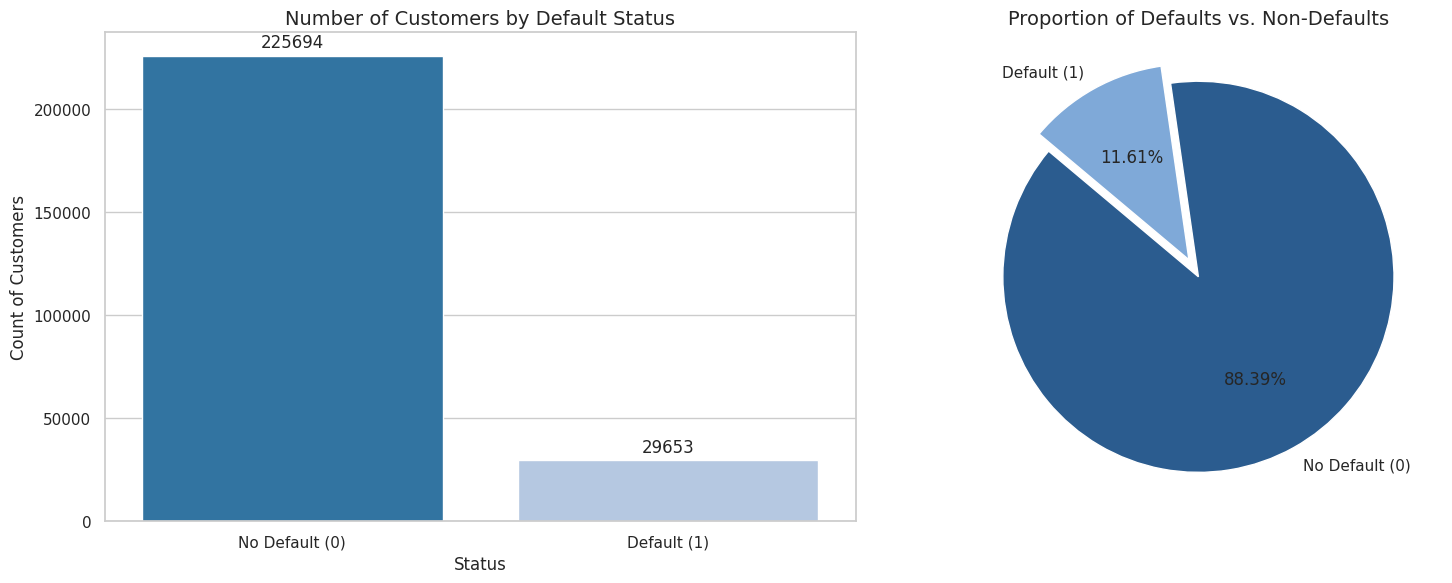

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style
sns.set_theme(style="whitegrid")

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Define elegant shades of blue
blue_colors = ['#1f77b4', '#aec7e8']

# 1. Bar Chart
sns.barplot(
    x=summary_df.index,
    y='Number of Customers',
    data=summary_df,
    palette=blue_colors,
    hue=summary_df.index,
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Number of Customers by Default Status', fontsize=14)
axes[0].set_ylabel('Count of Customers')
axes[0].set_xlabel('Status')

# Add values on top of the bars
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=3)

# 2. Pie Chart with premium shades of blue
axes[1].pie(
    summary_df['Number of Customers'],
    labels=summary_df.index,
    autopct='%1.2f%%',
    startangle=140,
    colors=['#2b5c8f', '#7fa9d8'],
    explode=(0, 0.1)
)
axes[1].set_title('Proportion of Defaults vs. Non-Defaults', fontsize=14)

plt.tight_layout()
plt.show()

### 1.6. Distribution Analysis (Skewness, Kurtosis, and Scatter Plot)
Let's calculate the skewness and kurtosis for our primary continuous numerical columns to understand how close they are to a normal distribution, and visualize their relationships with a scatter plot.

Age             -> Skewness:  0.0007 | Kurtosis: -1.1984
Income          -> Skewness: -0.0004 | Kurtosis: -1.1984
LoanAmount      -> Skewness: -0.0018 | Kurtosis: -1.2037
CreditScore     -> Skewness:  0.0047 | Kurtosis: -1.2003
DTIRatio        -> Skewness: -0.0015 | Kurtosis: -1.1997


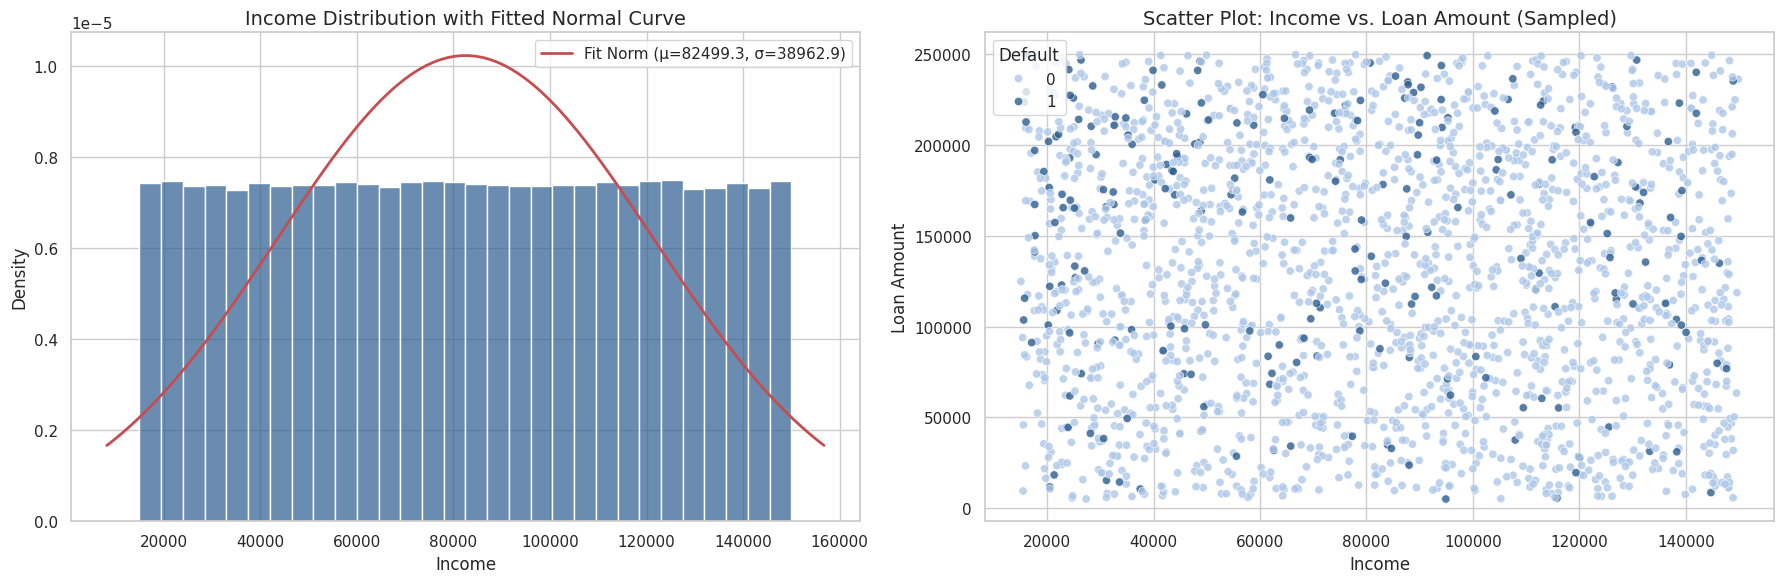

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import norm, skew, kurtosis

# Calculate Skewness and Kurtosis for major continuous features
features_to_analyze = ['Age', 'Income', 'LoanAmount', 'CreditScore', 'DTIRatio']
for col in features_to_analyze:
    s = skew(df[col])
    k = kurtosis(df[col])
    print(f"{col:15} -> Skewness: {s:7.4f} | Kurtosis: {k:7.4f}")

# Create subplots for visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Define shades of blue for consistency
blue_palette = ['#aec7e8', '#2b5c8f'] # Light blue for non-defaults, deep blue for defaults

# 1. Distribution Plot (Histogram with fitted Normal Curve)
sns.histplot(df['Income'], kde=False, stat='density', bins=30, color='#2b5c8f', alpha=0.7, ax=axes[0])
# Fit a normal distribution to the data
mu, std = norm.fit(df['Income'])
xmin, xmax = axes[0].get_xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
axes[0].plot(x, p, 'r-', linewidth=2, label=f'Fit Norm (μ={mu:.1f}, σ={std:.1f})')
axes[0].set_title('Income Distribution with Fitted Normal Curve', fontsize=14)
axes[0].set_xlabel('Income')
axes[0].legend()

# 2. Scatter Plot (Income vs. Loan Amount, colored by Default Status)
sns.scatterplot(
    x='Income',
    y='LoanAmount',
    hue='Default',
    data=df.sample(2000, random_state=42),  # Sample 2000 points for clearer visualization
    palette=blue_palette,
    alpha=0.8,
    ax=axes[1]
)
axes[1].set_title('Scatter Plot: Income vs. Loan Amount (Sampled)', fontsize=14)
axes[1].set_xlabel('Income')
axes[1].set_ylabel('Loan Amount')

plt.tight_layout()
plt.show()

### 1.6.5. Mapping Features to a Normal Distribution
Since numerical features like `Income` are uniformly distributed (platykurtic), we can map them to a normal distribution using the `QuantileTransformer` with `output_distribution='normal'`.

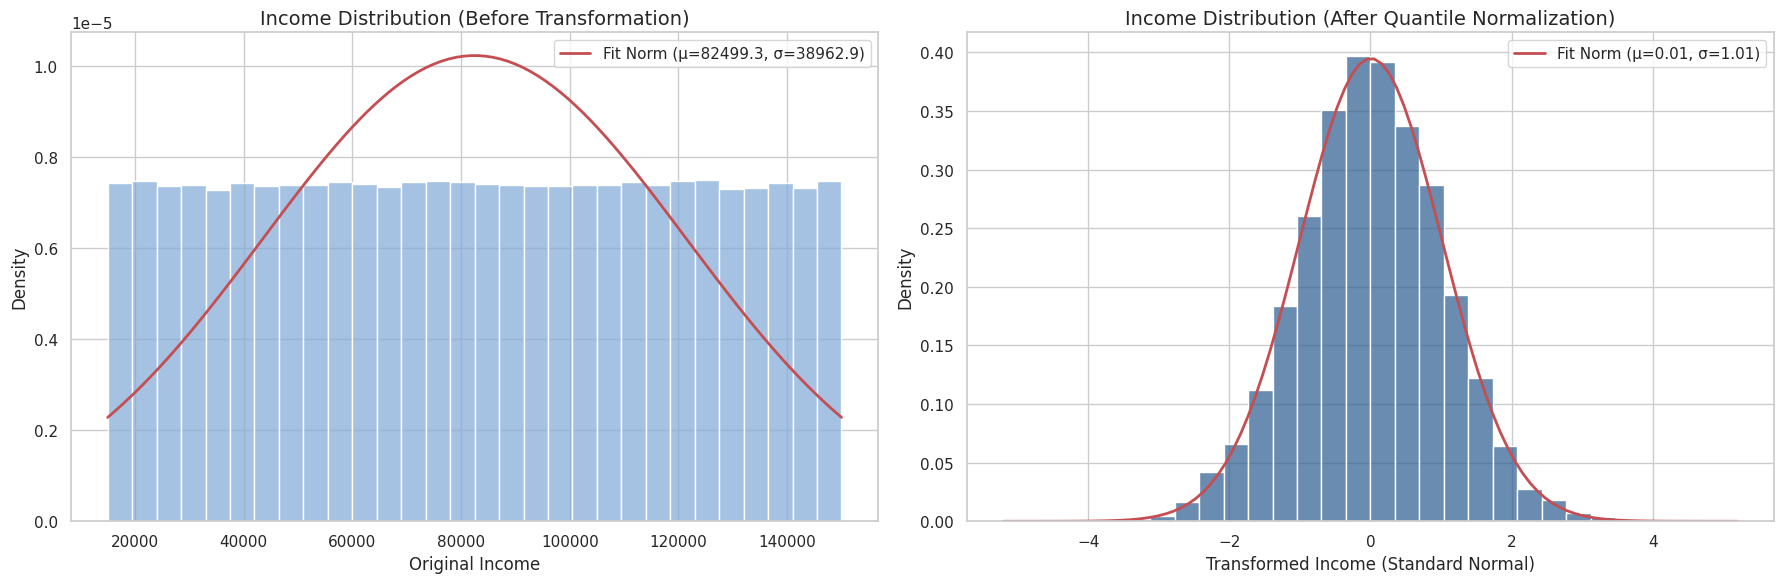

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import QuantileTransformer
from scipy.stats import norm

# Initialize the QuantileTransformer to map to a standard normal distribution
qt = QuantileTransformer(output_distribution='normal', random_state=42)
income_transformed = qt.fit_transform(df[['Income']]).flatten()

# Create a side-by-side comparison plot
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Before Transformation
sns.histplot(df['Income'], kde=False, stat='density', bins=30, color='#7fa9d8', alpha=0.7, ax=axes[0])
mu_before, std_before = norm.fit(df['Income'])
x_b = np.linspace(df['Income'].min(), df['Income'].max(), 100)
p_b = norm.pdf(x_b, mu_before, std_before)
axes[0].plot(x_b, p_b, 'r-', linewidth=2, label=f'Fit Norm (μ={mu_before:.1f}, σ={std_before:.1f})')
axes[0].set_title('Income Distribution (Before Transformation)', fontsize=14)
axes[0].set_xlabel('Original Income')
axes[0].legend()

# 2. After Transformation
sns.histplot(income_transformed, kde=False, stat='density', bins=30, color='#2b5c8f', alpha=0.7, ax=axes[1])
mu_after, std_after = norm.fit(income_transformed)
x_a = np.linspace(income_transformed.min(), income_transformed.max(), 100)
p_a = norm.pdf(x_a, mu_after, std_after)
axes[1].plot(x_a, p_a, 'r-', linewidth=2, label=f'Fit Norm (μ={mu_after:.2f}, σ={std_after:.2f})')
axes[1].set_title('Income Distribution (After Quantile Normalization)', fontsize=14)
axes[1].set_xlabel('Transformed Income (Standard Normal)')
axes[1].legend()

plt.tight_layout()
plt.show()

### 1.7. Advanced Categorical Relationship Analysis
Let's analyze how categorical features like `Education` and `LoanPurpose` correlate with the interest rates and the loan default rate using elegant blue visualizations.

### 1.8. Pearson Correlation Matrix
Let's analyze the linear relationships between all numerical features in our dataset using a Pearson correlation heatmap.

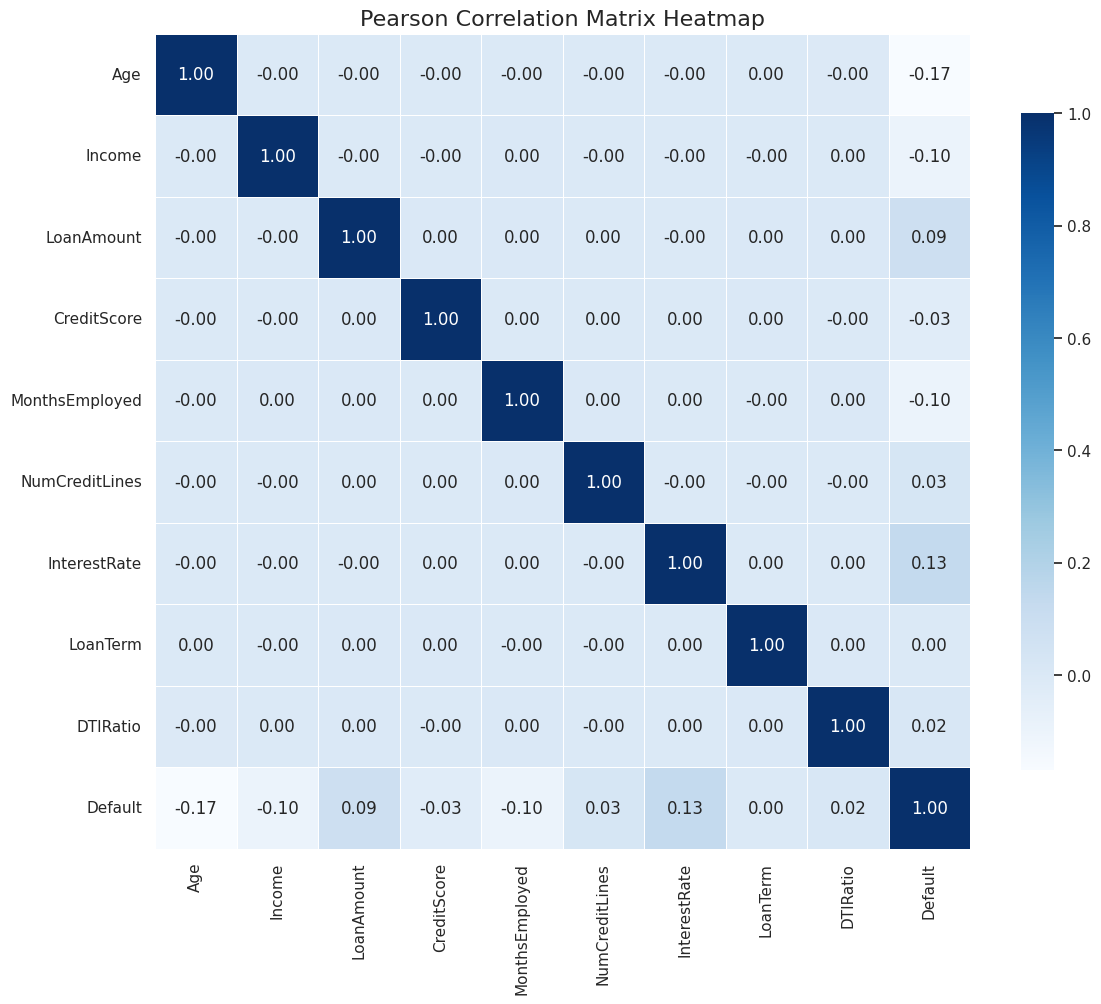

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure df is defined
try:
    _ = df
except NameError:
    df = pd.read_csv('/content/Loan_default.csv')

# Select only the numerical columns from our dataset
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
correlation_matrix = df[numerical_cols].corr(method='pearson')

# Set up the matplotlib figure
plt.figure(figsize=(12, 10))

# Draw the heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)

plt.title('Pearson Correlation Matrix Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

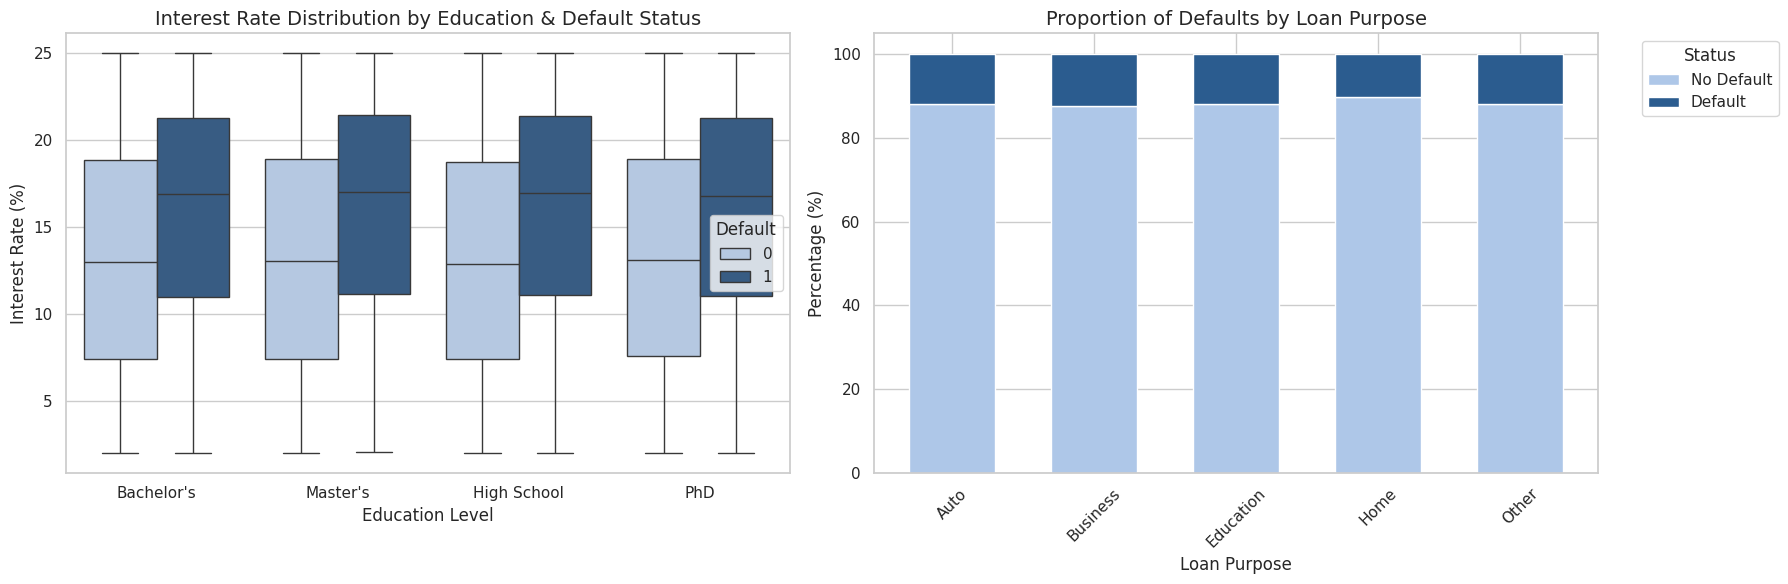

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set consistent aesthetic styling
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Define elegant blue shades
blue_colors = ['#aec7e8', '#2b5c8f']

# Graph 1: Box plot of Interest Rate across Education levels split by Default status
sns.boxplot(
    x='Education',
    y='InterestRate',
    hue='Default',
    data=df,
    palette=blue_colors,
    ax=axes[0]
)
axes[0].set_title('Interest Rate Distribution by Education & Default Status', fontsize=14)
axes[0].set_xlabel('Education Level')
axes[0].set_ylabel('Interest Rate (%)')

# Graph 2: Proportionate/Stacked bar plot of Loan Purpose by Default Status
purpose_default = df.groupby(['LoanPurpose', 'Default']).size().unstack(fill_value=0)
purpose_pct = purpose_default.div(purpose_default.sum(axis=1), axis=0) * 100

purpose_pct.plot(
    kind='bar',
    stacked=True,
    color=blue_colors,
    ax=axes[1],
    width=0.6
)
axes[1].set_title('Proportion of Defaults by Loan Purpose', fontsize=14)
axes[1].set_xlabel('Loan Purpose')
axes[1].set_ylabel('Percentage (%)')
axes[1].legend(['No Default', 'Default'], title='Status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 2. Data Preprocessing & Feature Engineering
We will handle missing values, drop columns that are identifiers (like `LoanID`), encode categorical features using Label/One-Hot encoding, and scale numerical columns.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import joblib

# Drop identifiers if present (e.g., 'LoanID')
if 'LoanID' in df.columns:
    df = df.drop(columns=['LoanID'])

# Identify categorical and numerical columns
# Assuming the target variable is named 'Default' (0 or 1)
target_col = 'Default' if 'Default' in df.columns else df.columns[-1]

X = df.drop(columns=[target_col])
y = df[target_col]

# Fill numerical missing values with median, categorical with mode
for col in X.columns:
    if X[col].dtype == 'object':
        X[col] = X[col].fillna(X[col].mode()[0])
    else:
        X[col] = X[col].fillna(X[col].median())

# Encode categorical variables
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    encoders[col] = le

# Scale numerical variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Save encoders and scaler for the Streamlit app
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(encoders, 'encoders.pkl')

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (204277, 16)
Testing set shape: (51070, 16)


### 3. Model Training & Comparison (Logistic Regression, Random Forest, XGBoost)

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

# Initialize models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42, n_jobs=-1)
}

# Train and evaluate models
best_accuracy = 0
best_model_name = ""
best_model = None

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"=== {name} ===")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred))

    if acc > best_accuracy:
        best_accuracy = acc
        best_model_name = name
        best_model = model

print(f"\nBest Model: {best_model_name} with Accuracy: {best_accuracy:.4f}")

# Save the best model for the Streamlit App
joblib.dump(best_model, 'best_model.pkl')
# Save features to maintain the same format in Streamlit
joblib.dump(X.columns.tolist(), 'feature_names.pkl')
print("Saved best_model.pkl, scaler.pkl, encoders.pkl, and feature_names.pkl successfully!")

=== Logistic Regression ===
Accuracy: 0.8851
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     45139
           1       0.60      0.03      0.06      5931

    accuracy                           0.89     51070
   macro avg       0.74      0.51      0.50     51070
weighted avg       0.85      0.89      0.84     51070

=== Random Forest ===
Accuracy: 0.8857
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     45139
           1       0.60      0.05      0.09      5931

    accuracy                           0.89     51070
   macro avg       0.74      0.52      0.51     51070
weighted avg       0.85      0.89      0.84     51070



/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:34:50] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


=== XGBoost ===
Accuracy: 0.8851
              precision    recall  f1-score   support

           0       0.89      0.99      0.94     45139
           1       0.53      0.08      0.14      5931

    accuracy                           0.89     51070
   macro avg       0.71      0.54      0.54     51070
weighted avg       0.85      0.89      0.85     51070


Best Model: Random Forest with Accuracy: 0.8857
Saved best_model.pkl, scaler.pkl, encoders.pkl, and feature_names.pkl successfully!


### 3.5. Confusion Matrix Visualization
Let's plot the confusion matrices for each of our models to better understand their predictions, particularly the trade-offs on class 1 (Loan Defaults).

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:35:56] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


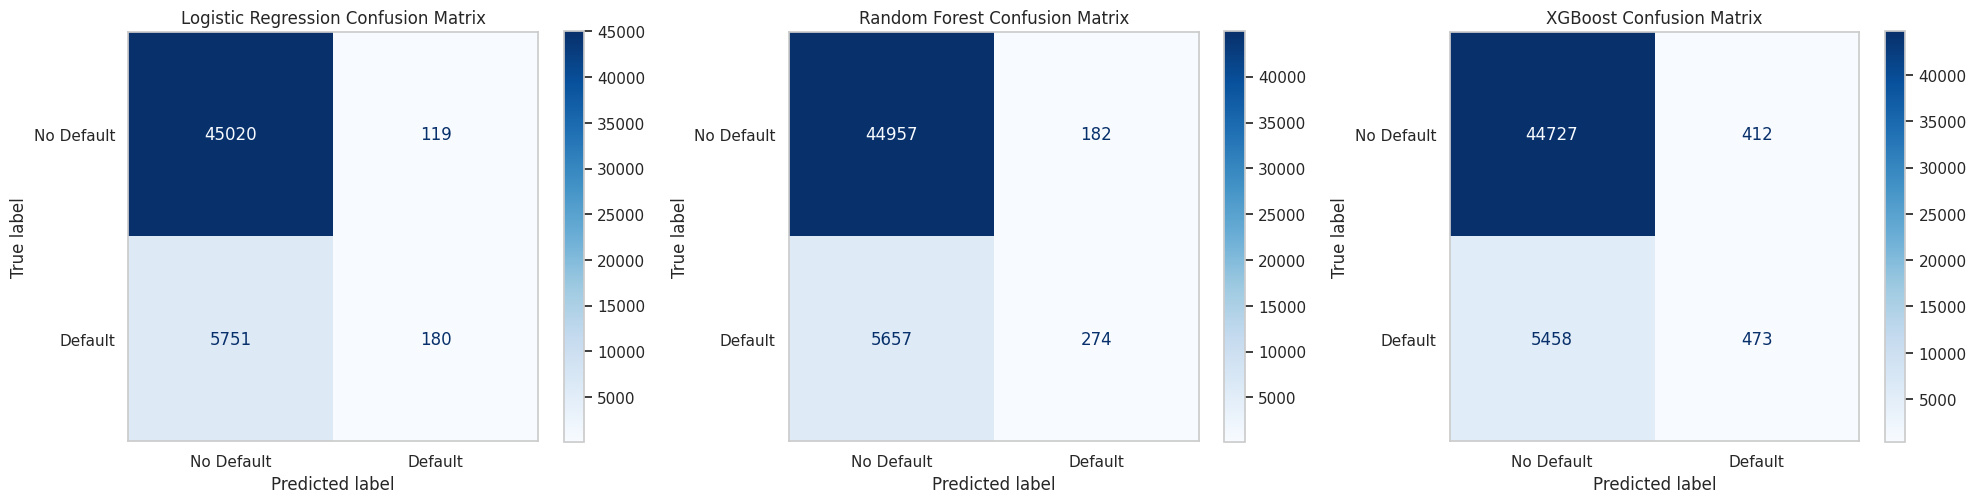

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Re-initialize and train models if they are not in scope to prevent NameErrors
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42, n_jobs=-1)
}

for name, model in models.items():
    model.fit(X_train, y_train)

# Plot confusion matrices side-by-side
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Default', 'Default'])
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    ax.set_title(f'{name} Confusion Matrix')
    ax.grid(False)

plt.tight_layout()
plt.show()

### 4. Download Files for Streamlit
Run the cell below to automatically download all the generated model, configuration, and app files to your local machine so you can run your Streamlit application.

In [12]:
from google.colab import files
import time

# List of files to download
files_to_download = [
    'best_model.pkl',
    'scaler.pkl',
    'encoders.pkl',
    'feature_names.pkl'
]

for file in files_to_download:
    print(f"Downloading {file}...")
    files.download(file)
    time.sleep(1)  # Brief pause to avoid overwhelming browser pop-up blocks

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>